In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**
https://github.com/roshananair/eds220-hwk2


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

In [2]:
# FINAL CODE

# Import pandas
import pandas as pd

# Read in salmon csv
catch_data = pd.read_csv('data/salmon_data.csv')


## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



<Axes: title={'center': 'Estimated Average Salmon Catches by Region from 1878 to 1997'}, xlabel='Mean Regional Catch (thousands)', ylabel='Region'>

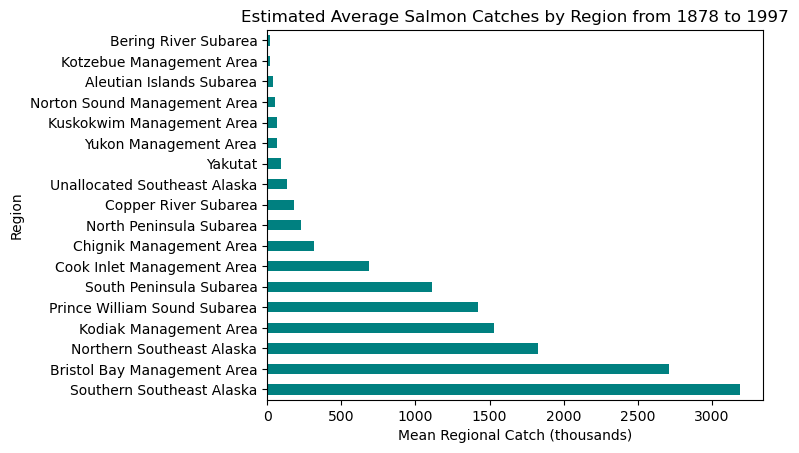

In [23]:
# a.

# Import pandas
import pandas as pd

# Read in salmon csv
catch_data = pd.read_csv('data/salmon_data.csv')

# Read in Region code definitions
reg_defs = pd.read_csv('data/df35b.303.1.csv')

# Updating Catch value at index 400 to 1
catch_data.at[400, 'Catch'] = 1

# Changing type of Catch column to integer
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# Select code and mgmtArea cols from reg_Defs and merge with catch_data on code and Region columns,
# drop code column (redundant with Region), fix Bering River Subarea and North Peninsula Subarea names
catch = (reg_defs[['code', 'mgmtArea']]
    .merge(catch_data, how = 'right', left_on = 'code', right_on = 'Region')
    .drop(['code'], axis = 1)
    .replace('Bering River Subarea Copper River Subarea', 'Bering River Subarea')
    .replace('NorthPeninsual Subarea', 'North Peninsula Subarea'))

# Create df containg mean catch by Region, order values
avg_region_2 = catch.groupby('mgmtArea')['Catch'].mean().sort_values(ascending = False)

# Plotting mean catch by Region using mgmtArea
(avg_region_2.plot(kind = 'barh',
                   title = 'Estimated Average Salmon Catches by Region from 1878 to 1997',
                   ylabel = 'Region', 
                   xlabel = 'Mean Regional Catch (thousands)', 
                   color = '#008080'))

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [4]:
# b.

print(catch_data.shape) # rows and columns

print(catch_data.info()) # col names, non-NA value counts, col types

print(catch_data['notesRegCode'].unique())  # unique values in notesRegCode col

print(catch_data['Region'].unique()) # unique values in Region col

print(f"Year start: {catch_data['Year'].min()} Year end: {catch_data['Year'].max()}") # year range

(8540, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Region        8540 non-null   object
 1   Year          8540 non-null   int64 
 2   notesRegCode  1415 non-null   object
 3   Species       8540 non-null   object
 4   Catch         8540 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 333.7+ KB
None
[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; 

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

**I wanted to see the dimensions of the dataframe, the names of the columns in the dataframe, their types, as well as how many NA values they contained. Since all columns except notesRegCode contained no NA values, I printed the unique values in that column to learn more about what type of information it contains. Then I looked at the Regions column to see how they are written (as codes). And finally, I looked at the year range for the data.**

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [5]:
# Unique values of notesRegCode column
notes_unique = catch_data['notesRegCode'].unique()
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [6]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [7]:
catch_data = catch_data[['Year', 'Region', 'Species', 'Catch']]
catch_data.columns.to_list

<bound method IndexOpsMixin.tolist of Index(['Year', 'Region', 'Species', 'Catch'], dtype='object')>

In [8]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


**Year, Region, and Species have the expected types int, string, and string. However, since Catch is a column of numbers, I'd expect an integer as as opposed to a string.**

In [9]:
catch_data.dtypes

Year        int64
Region     object
Species    object
Catch       int64
dtype: object

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [10]:
catch_data['Catch'].astype('int64')

0         0
1         0
2         0
3         0
4         0
       ... 
8535    135
8536     84
8537     99
8538     68
8539     97
Name: Catch, Length: 8540, dtype: int64

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [11]:
# Selecting rows where Catch column has value of 'I'
catch_I = catch_data.loc[(catch_data['Catch'] == 'I')]
catch_I 

,Year,Region,Species,Catch


In [12]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [13]:
# Updating Catch value at index 400 to 1
catch_data.at[400, 'Catch'] = 1

# Setting catch_! equal to index row 400
catch_1 = catch_data.loc[400]

# Print catch_1
catch_1

Year          1955
Region         GSE
Species    Chinook
Catch            1
Name: 400, dtype: object

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [14]:
# Changing type of Catch column to integer
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# Setting catch_column_type to the type of the Catch column
catch_column_type = catch_data['Catch'].dtype

# Print Catch column type
catch_column_type

dtype('int64')

In [15]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [16]:
# Creating df containing regional catch means, order values
avg_region = catch_data.groupby('Region')['Catch'].mean().sort_values(ascending = False)

# Dsiplaying regional catch mean df
avg_region

Region
SSE    3184.660714
BRB    2709.796491
NSE    1825.020870
KOD    1528.350000
PWS    1419.236697
SOP    1110.942222
CKI     683.571429
CHG     315.487273
NOP     229.493478
COP     179.223404
GSE     133.841463
YAK      91.922917
YUK      68.645570
KSK      67.642353
NRS      51.502703
ALU      40.383908
KTZ      18.836145
BER      16.372549
Name: Catch, dtype: float64

In [17]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

<Axes: title={'center': 'Estimated Average Salmon Catches by Region from 1878 to 1997'}, xlabel='Region', ylabel='Mean Regional Catch'>

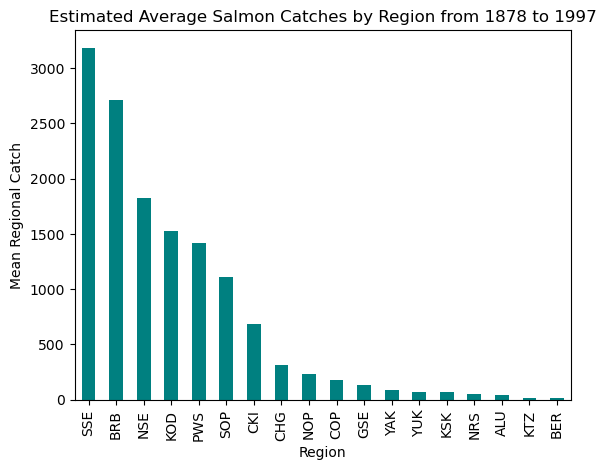

In [24]:
(avg_region.plot(kind = 'bar', 
title = 'Estimated Average Salmon Catches by Region from 1878 to 1997', 
xlabel = 'Region', 
ylabel = 'Mean Regional Catch', 
color = '#008080'))

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

<Axes: title={'center': 'Estimated Average Salmon Catches by Region from 1878 to 1997'}, xlabel='Mean Regional Catch (thousands)', ylabel='Region'>

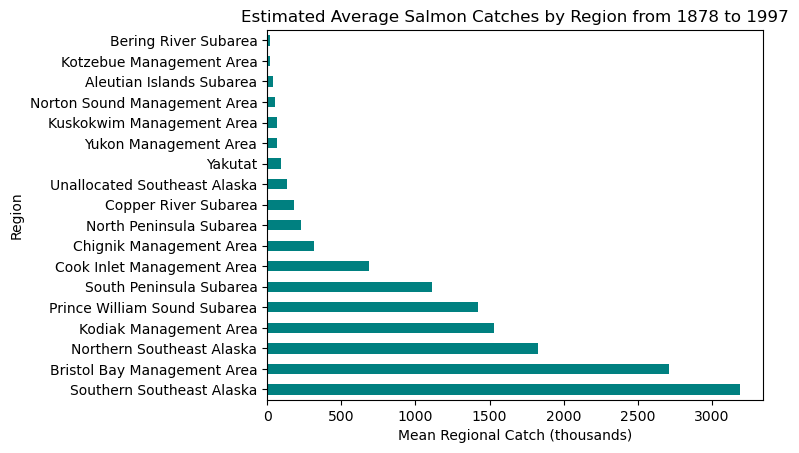

In [25]:
# Read in Region code definitions
reg_defs = pd.read_csv('data/df35b.303.1.csv')

# Select code and mgmtArea cols from reg_Defs and merge with catch_data on code and Region columns, 
# drop code column (redundant with Region), fix Bering River Subarea and North Peninsula Subarea names
catch = (reg_defs[['code', 'mgmtArea']]
    .merge(catch_data, how = 'right', left_on = 'code', right_on = 'Region')
    .drop(['code'], axis = 1)
    .replace('Bering River Subarea Copper River Subarea', 'Bering River Subarea')
    .replace('NorthPeninsual Subarea', 'North Peninsula Subarea'))

# Create df containg mean catch by Region, order values
avg_region_2 = catch.groupby('mgmtArea')['Catch'].mean().sort_values(ascending = False)

# Plotting mean catch by Region using mgmtArea
(avg_region_2.plot(kind = 'barh', 
                   title = 'Estimated Average Salmon Catches by Region from 1878 to 1997', 
                   ylabel = 'Region', 
                   xlabel = 'Mean Regional Catch (thousands)', 
                   color = '#008080'))

**Southern Southeast Alaska, followed by Bristol Bay Management Area have the highest mean regional salmon catch from 1878 to 1997. Conversely, the Kotzebue Management Area and Bering River Subarea have the lowest mean regional salmon catch from 1878 to 1997. Just a handfull of regions are responsible for the vast majority of salmon catch.**

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [20]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!